# Solving Inverse Problem using sLORETA

## 📦 Imports

In [1]:
import mindmap as mm
import mne
import numpy as np
from pathlib import Path

## 🧠 Data

In [2]:
# configuration
sub    = "vepcon_sub-10"
config = mm.io.read_config("../configurations/simf.yml")
sample = "sample1"

# data
data = mm.io.read_dataset(sub, "fwd", "cst", sample)

# features
data["gt"]  = data[sample][0]
data["eeg_inv"] = data[sample][1]

noise_cov = mne.make_ad_hoc_cov(data["eeg_inv"].info, std={"eeg":1})

#### 🌟 Visualize ground truth

In [3]:
mm.viz.plot_brain_time_series(data["fwd"]["src"], data["gt"].data, sfreq=200)

Widget(value='<iframe src="http://localhost:44175/index.html?ui=P_0x7b0f8054e0c0_0&reconnect=auto" class="pyvi…

#### 🌟 Visualize EEG time series

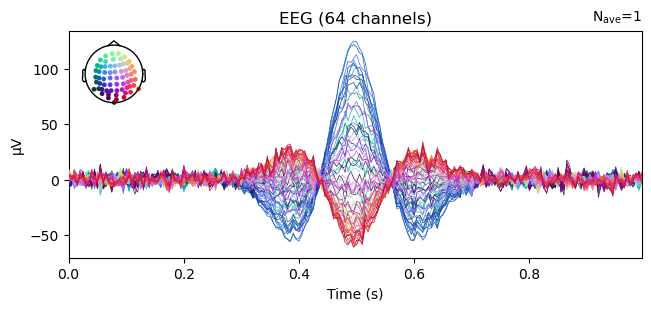

In [4]:
_ = data["eeg_inv"].plot()

#### 🌟 Visualize EEG topographic maps

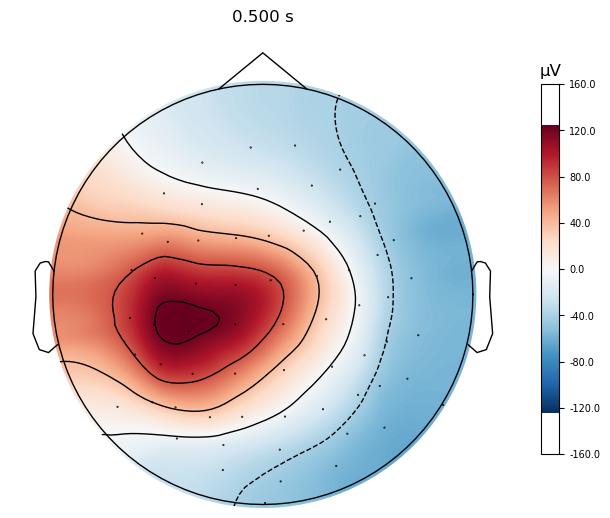

In [5]:
times = [0.5]
_ = data["eeg_inv"].plot_topomap(times=times, size=4)

#### 🌟 Visualize forward matrix

In [6]:
mm.viz.plot_leadfield(data["eeg_inv"], data["fwd"]).show()

    Average patch normals will be employed in the rotation to the local surface coordinates....
    Converting to surface-based source orientations...
    [done]


Widget(value='<iframe src="http://localhost:44175/index.html?ui=P_0x7b0e2209f200_2&reconnect=auto" class="pyvi…

## Solve the inverse problem with sLORETA
🛠️ <font color=violet>**Select CSET parameters**</font>: Select the regularizer parameter $\lambda$

In [7]:
lam = 0.1

In [8]:
data["eeg_inv"].set_eeg_reference(projection=True)

inverse = mne.minimum_norm.make_inverse_operator(
    data["eeg_inv"].info,
    data["fwd"],
    noise_cov,
    loose=0,
    depth=0.8,
)

stc = mne.minimum_norm.apply_inverse(
    data["eeg_inv"], 
    inverse, 
    lambda2=lam,
    method="sLORETA",
)

EEG channel type selected for re-referencing
Adding average EEG reference projection.
1 projection items deactivated
Average reference projection was added, but has not been applied yet. Use the apply_proj method to apply it.
Computing inverse operator with 64 channels.
    64 out of 64 channels remain after picking
Selected 64 channels
Creating the depth weighting matrix...
    64 EEG channels
    limit = 8891/8890 = 3.631408
    scale = 243995 exp = 0.8
    Picked elements from a free-orientation depth-weighting prior into the fixed-orientation one
    Average patch normals will be employed in the rotation to the local surface coordinates....
    Converting to surface-based source orientations...
    [done]
Whitening the forward solution.
    Created an SSP operator (subspace dimension = 1)
Computing rank from covariance with rank=None
    Using tolerance 0.00014 (2.2e-16 eps * 64 dim * 1e+10  max singular value)
    Estimated rank (eeg): 63
    EEG: rank 63 computed from 64 data cha

#### 🌟 Visualize reconstruction

In [9]:
mm.viz.plot_brain_time_series(data["fwd"]["src"], np.abs(stc.data), data["eeg_inv"].info["sfreq"], cmap="reds")

Widget(value='<iframe src="http://localhost:44175/index.html?ui=P_0x7b0e2044f5c0_3&reconnect=auto" class="pyvi…

#### 💾 Save the sLORETA reconstruction

In [13]:
fname  = f"{sub}_{sample}_sloreta-{lam}"
folder = Path(config["MM_DIR"])/sub/"stc"

if folder.exists() == False:
    folder.mkdir(parents=True)

print(f"Saving sLORETA reconstruction of {sample} from {sub}.")
stc.save(folder/fname, overwrite=True)

Saving sLORETA reconstruction of sample1 from vepcon_sub-10.
Writing STC to disk...
[done]


#### 💾 Save the sLORETA reconstruction in brain vision format

In [ ]:
save = "mne"
#save = "bv"

fname  = f"{sub}_sloreta-{lam}"
folder = mm_dir/sub/"stc"

if folder.exists() == False:
    folder.mkdir(parents=True)

print(f"Saving estimation for subject: {sub}")
if save == "mne":
    stc.save(folder/fname, overwrite=True)
if save == "bv":
    trans = mm.utils.compute_transformation(sub, fs_dir, "mri", "head", "m")
    mm.io.write_stc(
        fname  = fname,
        folder = folder,
        stc    = stc, 
        src    = forward["src"],
        trans  = trans, 
        overwrite = True, 
    )